# Preprocessing Artifact Audit
### Experiment v4b — localising the source of the acquisition cue

The trivial-feature control in v4a reached AUC 1.0000 across 25 development writers
using nine image statistics, with `fill_density` alone at 0.999. Before that is treated
as a property of the dataset, one alternative explanation must be eliminated: the
preprocessing pipeline may be producing it.

The pipeline performs four operations in sequence, three of which could plausibly
create a density difference where none exists.

| Stage | Operation | Could it produce a density difference? |
|---|---|---|
| S0 | original file, unprocessed grayscale | No — this is the reference condition |
| S1 | inversion to an ink-bright representation | No — a fixed affine map |
| S2 | Otsu threshold and density-filtered bounding-box crop | **Yes** — a per-image threshold alters what counts as ink, and the crop alters the denominator of fill density |
| S3 | padding to an aspect ratio of at most 2.5 | **Yes** — padding adds zero-ink area, in amounts that vary with signature shape |
| S4 | resize and centre on a 100×100 canvas | **Yes** — resampling redistributes intensity, at a scale factor that varies per image |

The nine statistics are therefore computed at every stage on the same images and their
AUC tracked through the pipeline, which localises any contribution rather than merely
confirming or denying one.

- Separation already present at S0 or S1 indicates a property of the dataset that the
  pipeline transmits.
- Separation absent at S0 and S1 and appearing at S2, S3 or S4 indicates that the named
  operation produces it, in which case v4a's control is void as a statement about the
  dataset.

Two tests are run. **Test A** is assumption-free: each writer's held-out genuine
signatures and forgeries are ranked directly by each single statistic. **Test B**
reproduces v4a's pair-descriptor and one-class SVM path at the first and last stage, to
establish that the control behaves identically.

Development writers only; the 30 confirmation writers are not read.

Runtime is a few minutes. No HOG features, no feature cache and no hyperparameter
search are involved — only image reads and nine statistics per image.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import numpy as np, pandas as pd, itertools, random, time, os
from PIL import Image, ImageOps
from math import floor, ceil
from skimage.filters import threshold_otsu
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
from pathlib import Path

RANDOM_SEED = 42; SPLIT_SEED = 20261014; N_DEV = 25
N_WRITERS = 55; N_TRAIN_GENUINE = 12
IMG_SIZE = (100,100); MAX_CROP_ASPECT = 2.5; DENSITY_FRAC = 0.05; INK_THRESH = 0.2
np.random.seed(RANDOM_SEED); random.seed(RANDOM_SEED)

DATASET_DIR = Path("/content/drive/MyDrive/cedar-dataset/signatures")
GENUINE_DIR = DATASET_DIR/"full_org"; FORGED_DIR = DATASET_DIR/"full_forg"
OUT_DIR = Path("/content/drive/MyDrive/4buwan_results_v45"); OUT_DIR.mkdir(parents=True, exist_ok=True)

T0 = time.time()
print("v4.5 loaded -- preprocessing-artifact audit")

v4.5 loaded -- preprocessing-artifact audit


In [3]:
genuine_files = sorted(GENUINE_DIR.glob("*.png")); forged_files = sorted(FORGED_DIR.glob("*.png"))
def get_writer_id(fp): return int(Path(fp).stem.split("_")[1])
assert len(genuine_files)==1320 and len(forged_files)==1320

rng_split = random.Random(RANDOM_SEED); writer_splits = {}
for wid in range(1, N_WRITERS+1):
    g = sorted([p for p in genuine_files if get_writer_id(p)==wid])
    f = sorted([p for p in forged_files  if get_writer_id(p)==wid])
    sg = g.copy(); rng_split.shuffle(sg); sf = f.copy(); rng_split.shuffle(sf)
    writer_splits[wid] = {"train_genuine": sg[:N_TRAIN_GENUINE],
                          "test_genuine":  sg[N_TRAIN_GENUINE:], "test_forged": sf}

_perm = np.random.default_rng(SPLIT_SEED).permutation(np.arange(1, N_WRITERS+1))
DEV = sorted(int(w) for w in _perm[:N_DEV]); CONFIRM = sorted(int(w) for w in _perm[N_DEV:])
print(f"DEV ({len(DEV)}): {DEV}")
print(f"CONFIRM ({len(CONFIRM)}) remains LOCKED and is not read in this notebook.")
assert DEV == [3,8,9,10,12,17,19,21,22,23,28,29,34,36,39,40,42,43,44,47,49,50,51,52,55], \
       "DEV set differs from v4 -- the split seed must match or the comparison is invalid"
print("DEV partition matches v4 exactly.")

DEV (25): [3, 8, 9, 10, 12, 17, 19, 21, 22, 23, 28, 29, 34, 36, 39, 40, 42, 43, 44, 47, 49, 50, 51, 52, 55]
CONFIRM (30) remains LOCKED and is not read in this notebook.
DEV partition matches v4 exactly.


## The staged pipeline

Each stage returns an ink-bright array in [0, 1] so that one `geom_stats`
implementation applies unchanged throughout. S0 is reported separately, because an
un-inverted grayscale image has dark ink and the threshold logic would be
backwards.

This is the *same code* as v4's `_common_geometry`, split at its three internal
boundaries rather than reimplemented — otherwise the audit would be testing a
different pipeline than the one that produced the result.

In [4]:
GEOM_NAMES = ["ink_total","ink_area","cent_y","cent_x","spread_y","spread_x",
              "bbox_aspect","mean_ink_intensity","fill_density"]

def geom_stats(i01, thr=INK_THRESH):
    ink = i01 > thr
    tot = float(i01.sum()); area = float(ink.sum())
    ys, xs = np.nonzero(ink)
    if len(ys)==0: return np.zeros(len(GEOM_NAMES))
    h = float(ys.max()-ys.min()+1); w = float(xs.max()-xs.min()+1)
    return np.array([tot, area, float(ys.mean()), float(xs.mean()),
                     float(ys.std()), float(xs.std()), w/max(h,1.0),
                     tot/max(area,1.0), tot/max(h*w,1.0)])

def _crop(img):
    ink = img > threshold_otsu(img) if img.max() > img.min() else np.zeros_like(img, bool)
    if ink.any():
        rc, cc = ink.sum(1), ink.sum(0)
        sr = rc >= max(2, rc.max()*DENSITY_FRAC); sc = cc >= max(2, cc.max()*DENSITY_FRAC)
        if sr.any() and sc.any():
            t,b = np.where(sr)[0][[0,-1]]; l,r = np.where(sc)[0][[0,-1]]
            return img[t:b+1, l:r+1]
    return img

def _pad_aspect(img, max_aspect=MAX_CROP_ASPECT):
    h,w = img.shape
    if w/h > max_aspect:
        pad = max(0, ceil(w/max_aspect)-h); return np.pad(img, ((pad//2, pad-pad//2),(0,0)), constant_values=0)
    if h/w > max_aspect:
        pad = max(0, ceil(h/max_aspect)-w); return np.pad(img, ((0,0),(pad//2, pad-pad//2)), constant_values=0)
    return img

def _resize_center(img, img_size=IMG_SIZE):
    tw, th = img_size; h,w = img.shape
    nw = min(tw, max(1, w*th//h)); nh = max(1, h*nw//w)
    img = np.asarray(Image.fromarray(img.astype(np.uint8)).resize((nw,nh)))
    top=floor((th-nh)/2); bot=ceil((th-nh)/2); lef=floor((tw-nw)/2); rig=ceil((tw-nw)/2)
    return np.pad(img, ((top,bot),(lef,rig)), mode="constant", constant_values=0)

STAGES = ["S1_inverted","S2_cropped","S3_padded","S4_final"]

def stage_arrays(path):
    """Returns S0 metadata plus the four ink-bright [0,1] stages."""
    with Image.open(path) as im:
        g = np.asarray(im.convert("L"))
        meta = {"width": g.shape[1], "height": g.shape[0],
                "filesize": os.path.getsize(path),
                "mean_gray": float(g.mean()), "std_gray": float(g.std()),
                "min_gray": float(g.min()), "frac_dark_128": float((g < 128).mean())}
        inv = np.asarray(ImageOps.invert(im.convert("L")))
    s1 = inv
    s2 = _crop(s1)
    s3 = _pad_aspect(s2)
    s4 = _resize_center(s3)
    return meta, {"S1_inverted": s1.astype(np.float32)/255.0,
                  "S2_cropped":  s2.astype(np.float32)/255.0,
                  "S3_padded":   s3.astype(np.float32)/255.0,
                  "S4_final":    s4.astype(np.float32)/255.0}

# sanity: S4 must equal v4's preprocess_signature output exactly
def preprocess_signature_v4(path):
    with Image.open(path) as im:
        img = np.asarray(ImageOps.invert(im.convert("L")))
    return _resize_center(_pad_aspect(_crop(img)))
p = writer_splits[DEV[0]]["train_genuine"][0]
_, st = stage_arrays(p)
assert np.allclose(st["S4_final"]*255.0, preprocess_signature_v4(p).astype(np.float32), atol=1e-4)
print("S4 reproduces v4's preprocess_signature exactly -- the audit tests the real pipeline.")

S4 reproduces v4's preprocess_signature exactly -- the audit tests the real pipeline.


## Extraction

Every development writer's held-out genuine signatures and forgeries, at all four
stages, plus the S0 file-level metadata. Training genuines are read as well so the
pooled distributions can be reported, but the AUCs use held-out data only.

In [5]:
rows_meta, rows_stats = [], []
sets = [("test_genuine", 1), ("test_forged", 0), ("train_genuine", 1)]
total = sum(len(writer_splits[w][s]) for w in DEV for s,_ in sets)
done = 0
for wid in DEV:
    for setname, label in sets:
        for p in writer_splits[wid][setname]:
            meta, st = stage_arrays(p)
            base = {"writer": wid, "set": setname, "genuine": label, "file": p.name}
            rows_meta.append({**base, **meta})
            for sname, arr in st.items():
                gs = geom_stats(arr)
                rows_stats.append({**base, "stage": sname,
                                   **{n: v for n, v in zip(GEOM_NAMES, gs)}})
            done += 1
            if done % 400 == 0: print(f"  ...{done}/{total}", flush=True)

META = pd.DataFrame(rows_meta); STATS = pd.DataFrame(rows_stats)
print(f"\nDone. {len(META)} images x {len(STAGES)} stages = {len(STATS)} stat rows "
      f"({time.time()-T0:.0f}s)")
META.to_csv(OUT_DIR/"s0_metadata.csv", index=False); STATS.to_csv(OUT_DIR/"staged_stats.csv", index=False)

  ...400/1200
  ...800/1200
  ...1200/1200

Done. 1200 images x 4 stages = 4800 stat rows (504s)


## S0 — the unprocessed files

A difference between genuine and forged scans at this stage precedes every operation in
the pipeline. `frac_dark_128` is the fraction of pixels below mid-grey: a direct,
threshold-free measure of the quantity of dark ink on the page.

In [6]:
held = META[META.set != "train_genuine"]
S0_COLS = ["width","height","filesize","mean_gray","std_gray","min_gray","frac_dark_128"]

print("="*86); print("S0 -- ORIGINAL FILE PROPERTIES, pooled over 25 DEV writers"); print("="*86)
g = held[held.genuine==1]; f = held[held.genuine==0]
print(f"  {'statistic':<20}{'genuine mean':>16}{'forged mean':>16}{'ratio':>10}{'MWU p':>12}")
for c in S0_COLS:
    u, pv = mannwhitneyu(g[c], f[c])
    print(f"  {c:<20}{g[c].mean():>16.4f}{f[c].mean():>16.4f}"
          f"{f[c].mean()/max(g[c].mean(),1e-9):>10.3f}{pv:>12.2e}")

print("\n" + "="*86); print("S0 -- per-writer AUC (sign-free): can a single file property rank genuine vs forged?")
print("="*86)
s0_auc = {}
for c in S0_COLS:
    per = []
    for wid in DEV:
        d = held[held.writer==wid]
        if d.genuine.nunique() < 2: continue
        a = roc_auc_score(d.genuine, d[c]); per.append(max(a, 1-a))
    s0_auc[c] = float(np.mean(per))
s0_series = pd.Series(s0_auc).sort_values(ascending=False)
print(s0_series.round(4).to_string())
print(f"\n  strongest S0 cue: {s0_series.idxmax()} at AUC {s0_series.max():.4f}")

S0 -- ORIGINAL FILE PROPERTIES, pooled over 25 DEV writers
  statistic               genuine mean     forged mean     ratio       MWU p
  width                       528.1500        539.8967     1.022    5.54e-01
  height                      360.9967        347.4700     0.963    6.00e-02
  filesize                 114390.9467      82089.0233     0.718    1.82e-18
  mean_gray                   235.7830        248.7591     1.055   1.14e-130
  std_gray                     20.0311         20.6084     1.029    4.90e-02
  min_gray                     75.1567         67.4733     0.898    1.43e-19
  frac_dark_128                 0.0165          0.0118     0.715    2.62e-08

S0 -- per-writer AUC (sign-free): can a single file property rank genuine vs forged?
mean_gray        1.0000
filesize         0.9042
height           0.8351
std_gray         0.8131
min_gray         0.8023
frac_dark_128    0.7746
width            0.7460

  strongest S0 cue: mean_gray at AUC 1.0000


## Test A — the statistics tracked through every stage

Each cell is the mean per-writer, sign-free AUC of one statistic at one pipeline stage,
computed on held-out signatures.

The `fill_density` row read left to right is the decisive one. A value near 1.0 already
at `S1_inverted` places the separation in the dataset, transmitted unchanged by the
pipeline. A value beginning near 0.5 and rising identifies the operation at which it is
introduced.

In [7]:
def stage_auc_table():
    out = {}
    for sname in STAGES:
        d_all = STATS[(STATS.stage==sname) & (STATS.set != "train_genuine")]
        col = {}
        for n in GEOM_NAMES:
            per = []
            for wid in DEV:
                d = d_all[d_all.writer==wid]
                if d.genuine.nunique() < 2: continue
                v = d[n].values
                if np.allclose(v, v[0]): per.append(0.5); continue
                a = roc_auc_score(d.genuine, v); per.append(max(a, 1-a))
            col[n] = float(np.mean(per))
        out[sname] = col
    return pd.DataFrame(out)[STAGES]

A = stage_auc_table()
print("="*88); print("TEST A -- per-writer sign-free AUC of each statistic, by pipeline stage"); print("="*88)
print(A.round(4).to_string())
A.to_csv(OUT_DIR/"testA_stage_auc.csv")

print("\n  per-stage maximum over statistics:")
for sname in STAGES:
    print(f"    {sname:14s} best = {A[sname].idxmax():20s} AUC {A[sname].max():.4f}")

print("\n" + "="*88); print("CHANGE INTRODUCED BY EACH OPERATION (delta AUC vs previous stage)"); print("="*88)
for i in range(1, len(STAGES)):
    prev, cur = STAGES[i-1], STAGES[i]
    d = (A[cur] - A[prev]).sort_values(ascending=False)
    op = {"S2_cropped":"Otsu threshold + density crop","S3_padded":"aspect padding",
          "S4_final":"resize + centre"}[cur]
    print(f"\n  {prev} -> {cur}   ({op})")
    print(f"    largest increase: {d.index[0]:20s} {d.iloc[0]:+.4f}")
    print(f"    largest decrease: {d.index[-1]:20s} {d.iloc[-1]:+.4f}")
    print(f"    mean |change| across statistics: {d.abs().mean():.4f}")

TEST A -- per-writer sign-free AUC of each statistic, by pipeline stage
                    S1_inverted  S2_cropped  S3_padded  S4_final
ink_total                0.9943      0.9440     0.9440    0.9912
ink_area                 0.8080      0.8069     0.8069    0.7844
cent_y                   0.8161      0.7793     0.7267    0.7467
cent_x                   0.7072      0.7768     0.7768    0.6369
spread_y                 0.8200      0.8225     0.8225    0.8014
spread_x                 0.7758      0.7762     0.7762    0.7233
bbox_aspect              0.7229      0.8268     0.8268    0.8212
mean_ink_intensity       1.0000      1.0000     1.0000    0.9401
fill_density             0.9964      0.9993     0.9993    0.9993

  per-stage maximum over statistics:
    S1_inverted    best = mean_ink_intensity   AUC 1.0000
    S2_cropped     best = mean_ink_intensity   AUC 1.0000
    S3_padded      best = mean_ink_intensity   AUC 1.0000
    S4_final       best = fill_density         AUC 0.9993

CHANGE 

## Test B — the control path reproduced at the first and last stage

Test A establishes whether the raw statistics differ. Test B establishes whether v4a's
control as implemented — the 18-dimensional symmetric pair descriptor, a per-writer
`StandardScaler`, a one-class SVM at ν = 0.10 with the `scale` heuristic for γ, and
majority vote over twelve enrolled pairs — reproduces AUC 1.0000, and whether it
continues to do so on minimally processed images.

Reproduction at S1 would establish that the control was not measuring the effect of
preprocessing.

In [8]:
EPS = 1e-12
def geom_pair_descriptor(a, b):
    out = []
    for i in range(len(a)):
        x, y = float(a[i]), float(b[i]); s = abs(x)+abs(y)+EPS
        out.append(abs(x-y)/s)
        out.append(min(abs(x),abs(y))/(max(abs(x),abs(y))+EPS))
    return np.array(out)

def _decide(preds): return 1 if int((preds==1).sum()) > len(preds)/2 else -1

def stage_matrix(sname, wid, setname):
    d = STATS[(STATS.stage==sname)&(STATS.writer==wid)&(STATS.set==setname)]
    return d[GEOM_NAMES].values.astype(np.float64)

def control_eval(sname, nu=0.10, gamma="scale"):
    rows = []
    for wid in DEV:
        W  = stage_matrix(sname, wid, "train_genuine")
        Tg = stage_matrix(sname, wid, "test_genuine")
        Tf = stage_matrix(sname, wid, "test_forged")
        D = np.array([geom_pair_descriptor(W[i], W[j])
                      for i, j in itertools.combinations(range(len(W)), 2)])
        sc = StandardScaler().fit(D)
        m  = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(sc.transform(D))
        def run(T):
            dec, sco = [], []
            for q in T:
                Q = sc.transform(np.array([geom_pair_descriptor(q, t) for t in W]))
                dec.append(_decide(m.predict(Q))); sco.append(float(m.decision_function(Q).mean()))
            return np.array(dec), np.array(sco)
        gd, gs = run(Tg); fd, fs = run(Tf)
        tp=int((gd==1).sum()); fn=int((gd==-1).sum()); fp=int((fd==1).sum()); tn=int((fd==-1).sum())
        rows.append({"writer": wid, "FRR": fn/(tp+fn), "FAR": fp/(fp+tn),
                     "Accuracy": (tp+tn)/(tp+tn+fp+fn),
                     "AUC": roc_auc_score(np.r_[np.ones(len(gs)), np.zeros(len(fs))], np.r_[gs, fs])})
    df = pd.DataFrame(rows)
    ov = {k: float(df[k].mean()) for k in ("FRR","FAR","Accuracy","AUC")}
    ov["BalancedAccuracy"] = ((1-ov["FRR"])+(1-ov["FAR"]))/2
    return df, ov

print("="*86); print("TEST B -- v4's ink control, rebuilt at the earliest and latest stage"); print("="*86)
tb = []
for sname in ("S1_inverted", "S4_final"):
    _, ov = control_eval(sname)
    tb.append({"stage": sname, **ov})
    print(f"  {sname:14s} AUC {ov['AUC']:.4f}   BalAcc {ov['BalancedAccuracy']:.4f}   "
          f"FRR {ov['FRR']:.4f}   FAR {ov['FAR']:.4f}", flush=True)
TB = pd.DataFrame(tb); TB.to_csv(OUT_DIR/"testB_control_by_stage.csv", index=False)
print(f"\n  v4 reported, at S4: AUC 1.0000  BalAcc 0.7117  FRR 0.5767  FAR 0.0000")
print(f"  S4 reproduction delta: AUC {tb[-1]['AUC']-1.0:+.4f}  BalAcc {tb[-1]['BalancedAccuracy']-0.7117:+.4f}")

TEST B -- v4's ink control, rebuilt at the earliest and latest stage
  S1_inverted    AUC 1.0000   BalAcc 0.6950   FRR 0.6100   FAR 0.0000
  S4_final       AUC 1.0000   BalAcc 0.7117   FRR 0.5767   FAR 0.0000

  v4 reported, at S4: AUC 1.0000  BalAcc 0.7117  FRR 0.5767  FAR 0.0000
  S4 reproduction delta: AUC +0.0000  BalAcc -0.0000


## The physical difference

If the effect is real, it should be visible as two separated distributions rather
than as a statistic. This plots the strongest cue at the earliest and latest stage,
pooled across development writers, with the per-writer overlap reported — because
a pooled gap could in principle come from between-writer variation rather than from
a genuine-versus-forged difference within each writer.

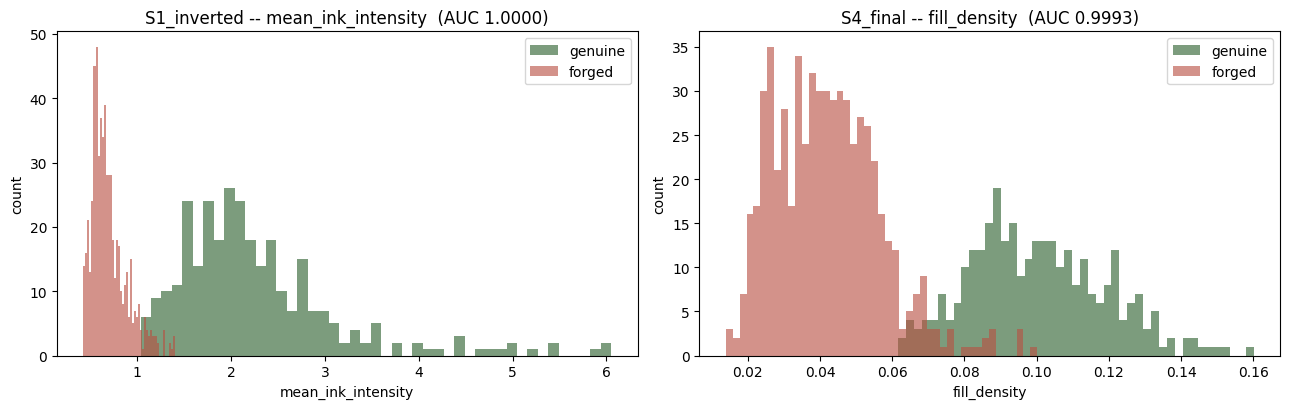

WITHIN-WRITER SEPARATION -- is the gap present inside each writer?
  S1_inverted / mean_ink_intensity
    writers with ZERO overlap between genuine and forged: 25/25
    writers where forged mean exceeds genuine mean      : 0/25
  S4_final / fill_density
    writers with ZERO overlap between genuine and forged: 24/25
    writers where forged mean exceeds genuine mean      : 0/25


In [9]:
best_s1 = A["S1_inverted"].idxmax(); best_s4 = A["S4_final"].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (sname, col) in zip(axes, [("S1_inverted", best_s1), ("S4_final", best_s4)]):
    d = STATS[(STATS.stage==sname)&(STATS.set!="train_genuine")]
    ax.hist(d[d.genuine==1][col], bins=45, alpha=0.62, label="genuine", color="#2C5F2D")
    ax.hist(d[d.genuine==0][col], bins=45, alpha=0.62, label="forged",  color="#B85042")
    ax.set_title(f"{sname} -- {col}  (AUC {A.loc[col, sname]:.4f})")
    ax.set_xlabel(col); ax.set_ylabel("count"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR/"distributions.png", dpi=130); plt.show()

print("="*86); print("WITHIN-WRITER SEPARATION -- is the gap present inside each writer?"); print("="*86)
for sname, col in [("S1_inverted", best_s1), ("S4_final", best_s4)]:
    d_all = STATS[(STATS.stage==sname)&(STATS.set!="train_genuine")]
    clean = 0; rows = []
    for wid in DEV:
        d = d_all[d_all.writer==wid]
        gv = d[d.genuine==1][col].values; fv = d[d.genuine==0][col].values
        sep = (gv.max() < fv.min()) or (fv.max() < gv.min())
        clean += int(sep)
        rows.append({"writer": wid, "genuine_mean": gv.mean(), "forged_mean": fv.mean(),
                     "perfectly_separated": sep})
    r = pd.DataFrame(rows)
    print(f"  {sname} / {col}")
    print(f"    writers with ZERO overlap between genuine and forged: {clean}/{len(DEV)}")
    print(f"    writers where forged mean exceeds genuine mean      : "
          f"{int((r.forged_mean > r.genuine_mean).sum())}/{len(DEV)}")
    r.to_csv(OUT_DIR/f"within_writer_{sname}.csv", index=False)

## Verdict

In [10]:
s1 = float(A.loc[A["S1_inverted"].idxmax(), "S1_inverted"])
s4 = float(A.loc[A["S4_final"].idxmax(), "S4_final"])
s0 = float(s0_series.max())
tb_s1 = float(TB[TB.stage=="S1_inverted"].AUC.iloc[0]); tb_s4 = float(TB[TB.stage=="S4_final"].AUC.iloc[0])

print("="*86); print("VERDICT -- is v4's ink control real, or did we manufacture it?"); print("="*86)
print(f"  S0 original-file properties, best single AUC : {s0:.4f}  ({s0_series.idxmax()})")
print(f"  S1 minimally processed, best statistic AUC   : {s1:.4f}  ({A['S1_inverted'].idxmax()})")
print(f"  S4 full pipeline, best statistic AUC         : {s4:.4f}  ({A['S4_final'].idxmax()})")
print(f"  S1 full control path (Test B) AUC            : {tb_s1:.4f}")
print(f"  S4 full control path (Test B) AUC            : {tb_s4:.4f}   [v4 reported 1.0000]")
print("-"*86)

if s1 >= 0.95 or s0 >= 0.95:
    print("  [CONFIRMED] The separation exists BEFORE our pipeline does anything meaningful.")
    print("              It is a property of CEDAR, not of our preprocessing.")
    print("              v4's control stands. This is a finding and it is reportable:")
    print("              genuine and forged signatures in CEDAR are separable on")
    print("              acquisition-level cues, independent of signature shape.")
    print("              -> v5 proceeds: headline moves to HOG, ink-normalised arm added.")
elif s4 >= 0.95 and s1 < 0.75:
    worst = (A['S4_final'] - A['S1_inverted']).idxmax()
    print("  [OUR BUG]   The separation is ABSENT on the original images and APPEARS")
    print("              during preprocessing. v4's control is VOID as a dataset finding.")
    print(f"              Statistic most inflated by the pipeline: {worst}")
    print("              Read the per-operation deltas in Test A to see which stage did it.")
    print("              -> v5 must FIX the pipeline first; no claim about CEDAR is defensible.")
elif s1 >= 0.75:
    print("  [PARTIAL]   A real but weaker separation exists in the original images, and the")
    print("              pipeline amplifies it. Both halves must be reported: CEDAR carries")
    print("              an acquisition cue, and our preprocessing makes it stronger.")
    print("              -> v5 proceeds with the ink-normalised arm as the PRIMARY evaluation.")
else:
    print("  [NEITHER]   Neither the original images nor the pipeline produce strong")
    print("              separation at this stage. Re-examine the v4 control -- the result")
    print("              does not reproduce and something differs between the two notebooks.")

print("\n" + "-"*86)
print("  Regardless of branch, these go in Chapter 4 as a validity subsection:")
print(f"    - the staged AUC table (Test A), which localises any pipeline contribution")
print(f"    - the within-writer overlap counts, which rule out between-writer confounding")
print(f"    - the ink control's own operating point: perfect ranking, broken boundary")

t = time.time()-T0; print(f"\n[runtime] {int(t//60)}m {int(t%60)}s   Colab High-RAM, CPU")
print(f"Artifacts -> {OUT_DIR}")
for fp in sorted(OUT_DIR.glob("*")): print("  ", fp.name)

VERDICT -- is v4's ink control real, or did we manufacture it?
  S0 original-file properties, best single AUC : 1.0000  (mean_gray)
  S1 minimally processed, best statistic AUC   : 1.0000  (mean_ink_intensity)
  S4 full pipeline, best statistic AUC         : 0.9993  (fill_density)
  S1 full control path (Test B) AUC            : 1.0000
  S4 full control path (Test B) AUC            : 1.0000   [v4 reported 1.0000]
--------------------------------------------------------------------------------------
  [CONFIRMED] The separation exists BEFORE our pipeline does anything meaningful.
              It is a property of CEDAR, not of our preprocessing.
              v4's control stands. This is a finding and it is reportable:
              genuine and forged signatures in CEDAR are separable on
              acquisition-level cues, independent of signature shape.
              -> v5 proceeds: headline moves to HOG, ink-normalised arm added.

----------------------------------------------------